# Comparing conditions after FlowSOM clustering

After clustering, the usual next question is what differs between conditions. There are two kinds of differences:

1. Differential abundance (DA): does the share of a cell population change between conditions?
2. Differential state (DS): within a population, does the level of a functional marker (for example a phosphorylated signalling protein) change?

In this tutorial we answer both questions with existing scverse tools: pytometry for reading and clustering, scanpy for per-sample summaries and [pertpy](https://pertpy.readthedocs.io) for the statistical tests.

The data is the subset of [Bodenmiller et al. (2012)](https://doi.org/10.1038/nbt.2317) used in the Bioconductor [CyTOF workflow](https://www.bioconductor.org/packages/release/workflows/html/cytofWorkflow.html) ([Nowicka et al., 2017](https://doi.org/10.12688/f1000research.11622.3)): mass cytometry of peripheral blood cells from 8 healthy donors. From each donor there is one unstimulated reference sample (`Ref`) and one sample stimulated for 30 minutes with a B cell receptor / Fc receptor cross-linker (`BCRXL`), so 16 samples in total. The panel has 10 "type" markers to identify cell populations and 14 "state" markers that measure signalling.

One rule matters throughout: the unit of replication is the sample (here: the donor), not the cell. Each sample contains thousands of cells, but cells from the same sample are not independent replicates. A test on cells would treat 170,000 cells as independent observations and find tiny, irrelevant differences "significant" (pseudoreplication). We therefore first summarise each sample, and then test on these 16 summaries. Because every donor contributes one sample to each condition, we also use a paired design: each donor is compared with themselves.

The tests need pertpy, which is not a dependency of pytometry. scCODA, the abundance model we use, also needs jax and numpyro:

```
pip install "pertpy[jax]"
```

In [1]:
import anndata as ad
import matplotlib.pyplot as plt
import pandas as pd
import pertpy as pt
import scanpy as sc
import seaborn as sns
from statsmodels.stats.multitest import fdrcorrection

import pytometry as pm

## Download the data

The sample metadata and the panel come from the [Zenodo record](https://doi.org/10.5281/zenodo.10039274) of the CyTOF workflow. The 16 FCS files were originally hosted by the Robinson lab at the University of Zurich, which no longer serves them, so we download an archived copy of the same zip file from the Internet Archive.

In [2]:
import zipfile
from pathlib import Path
from urllib.request import urlretrieve

zenodo = "https://zenodo.org/records/10039274/files/"
fcs_zip = (
    "https://web.archive.org/web/20250821213226id_/"
    "http://imlspenticton.uzh.ch/robinson_lab/cytofWorkflow/PBMC8_fcs_files.zip"
)
for url, file in [
    (zenodo + "PBMC8_metadata.xlsx", "PBMC8_metadata.xlsx"),
    (zenodo + "PBMC8_panel_v3.xlsx", "PBMC8_panel_v3.xlsx"),
    (fcs_zip, "PBMC8_fcs_files.zip"),
]:
    if not Path(file).exists():
        urlretrieve(url, file)
with zipfile.ZipFile("PBMC8_fcs_files.zip") as zf:
    zf.extractall()

The metadata table links every FCS file to its sample, condition and donor:

In [3]:
metadata = pd.read_excel("PBMC8_metadata.xlsx")
metadata["condition"] = pd.Categorical(metadata["condition"], categories=["Ref", "BCRXL"])
metadata.head()

,file_name,sample_id,condition,patient_id
0,PBMC8_30min_patient1_BCR-XL.fcs,BCRXL1,BCRXL,Patient1
1,PBMC8_30min_patient1_Reference.fcs,Ref1,Ref,Patient1
2,PBMC8_30min_patient2_BCR-XL.fcs,BCRXL2,BCRXL,Patient2
3,PBMC8_30min_patient2_Reference.fcs,Ref2,Ref,Patient2
4,PBMC8_30min_patient3_BCR-XL.fcs,BCRXL3,BCRXL,Patient3


The panel says which markers are type markers and which are state markers:

In [4]:
panel = pd.read_excel("PBMC8_panel_v3.xlsx")
type_markers = panel.loc[panel["marker_class"] == "type", "antigen"].tolist()
state_markers = panel.loc[panel["marker_class"] == "state", "antigen"].tolist()
print("type: ", type_markers)
print("state:", state_markers)

type:  ['CD3', 'CD45', 'CD4', 'CD20', 'CD33', 'CD123', 'CD14', 'IgM', 'HLA-DR', 'CD7']
state: ['pNFkB', 'pp38', 'pStat5', 'pAkt', 'pStat1', 'pSHP2', 'pZap70', 'pStat3', 'pSlp76', 'pBtk', 'pPlcg2', 'pErk', 'pLat', 'pS6']


## Read, merge and transform

We read each FCS file with `pm.io.read_fcs` and concatenate them into one AnnData with `anndata.concat`, which records the sample of every cell in `obs["sample_id"]`. These files report a data offset that is off by one byte, a known quirk of this dataset, so we pass `ignore_offset_error=True`. Then we add the condition and donor of every cell from the metadata.

In [5]:
adatas = {row.sample_id: pm.io.read_fcs(row.file_name, ignore_offset_error=True) for row in metadata.itertuples()}
adata = ad.concat(adatas, label="sample_id", index_unique="-")
sample_info = metadata.set_index("sample_id")[["condition", "patient_id"]]
adata.obs = adata.obs.join(sample_info, on="sample_id")
adata

AnnData object with n_obs × n_vars = 172791 × 35
    obs: 'sample_id', 'condition', 'patient_id'
    layers: None (.X)

We keep the 24 markers of the panel (dropping time, DNA and barcoding channels) and transform them with the inverse hyperbolic sine with cofactor 5, as is usual for mass cytometry.

In [6]:
adata = adata[:, panel["antigen"]].copy()
pm.tl.normalize_arcsinh(adata, cofactor=5)

## Cluster with FlowSOM

Cell populations should be defined by the type markers only. If we also clustered on the state markers, stimulated and unstimulated cells of the same population could end up in different clusters, and the comparison we want to make would be built into the clustering. `markers=type_markers` restricts FlowSOM to the type markers, while all markers stay in `adata`. We let consensus clustering choose between 8 and 20 meta-clusters.

In [7]:
pm.tl.flowsom_clustering(
    adata,
    key_added="cluster",
    markers=type_markers,
    min_clusters=8,
    max_clusters=20,
    seed=42,
)
adata.obs["cluster"].value_counts().head()

cluster
cluster_7    42749
cluster_2    37485
cluster_4    19597
cluster_8    16943
cluster_1    15156
Name: count, dtype: int64

To name the clusters, we look at the mean of each type marker per cluster, scaled to between 0 and 1 per marker:

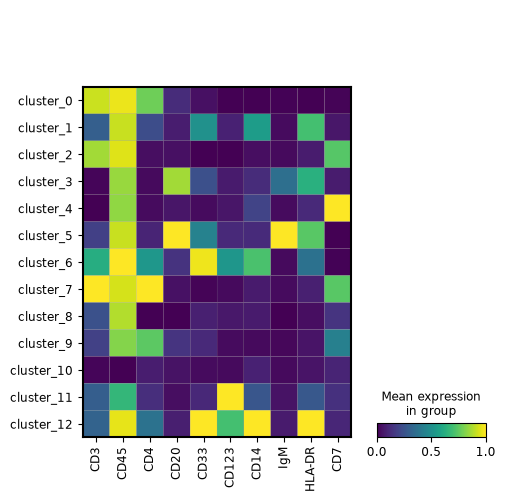

In [8]:
sc.pl.matrixplot(adata, type_markers, groupby="cluster", standard_scale="var");

Most clusters are easy to name from these markers: B cells are CD20+ (and split by IgM), T cells CD3+ (CD4+, or CD4- which we call CD8 T cells although CD8 is not in the panel), NK cells CD7+ CD3-, monocytes HLA-DR+ CD14+. A few clusters have no clear phenotype, and we name them after their markers instead. If you rerun the clustering on another machine and get different cluster numbers, adapt the names to your heatmap.

In [9]:
names = {
    "cluster_0": "CD4 T, CD7-",
    "cluster_1": "monocytes",
    "cluster_2": "CD8 T",
    "cluster_3": "B, IgM-",
    "cluster_4": "NK",
    "cluster_5": "B, IgM+",
    "cluster_6": "mixed",
    "cluster_7": "CD4 T",
    "cluster_8": "CD3 dim",
    "cluster_9": "CD4 T, CD3 dim",
    "cluster_10": "CD45 low",
    "cluster_11": "CD123+ HLA-DR-",
    "cluster_12": "DC",
}
adata.obs["population"] = adata.obs["cluster"].map(names).astype("category")

## Summarise each sample

Now we reduce the 170,000 cells to one row per sample. For abundance, we count the cells of each population in each sample:

In [10]:
counts = pd.crosstab(adata.obs["sample_id"], adata.obs["population"])
counts.head()

population,"CD4 T, CD7-",monocytes,CD8 T,"B, IgM-",NK,"B, IgM+",mixed,CD4 T,CD3 dim,"CD4 T, CD3 dim",CD45 low,CD123+ HLA-DR-,DC
sample_id,,,,,,,,,,,,,
BCRXL1,52,76,1197,75,389,69,11,651,175,47,50,14,32
BCRXL2,618,780,5905,301,1512,100,201,4860,1337,321,328,277,135
BCRXL3,554,1658,2054,494,1778,264,142,3217,1110,170,283,301,227
BCRXL4,316,1216,1370,241,1359,206,86,2377,1011,141,173,267,227
BCRXL5,303,902,2231,329,832,142,56,2409,643,182,161,195,158


and divide by the number of cells per sample to get proportions:

In [11]:
proportions = counts.div(counts.sum(axis=1), axis=0)
proportions.round(3).head()

population,"CD4 T, CD7-",monocytes,CD8 T,"B, IgM-",NK,"B, IgM+",mixed,CD4 T,CD3 dim,"CD4 T, CD3 dim",CD45 low,CD123+ HLA-DR-,DC
sample_id,,,,,,,,,,,,,
BCRXL1,0.018,0.027,0.422,0.026,0.137,0.024,0.004,0.229,0.062,0.017,0.018,0.005,0.011
BCRXL2,0.037,0.047,0.354,0.018,0.091,0.006,0.012,0.291,0.080,0.019,0.020,0.017,0.008
BCRXL3,0.045,0.135,0.168,0.040,0.145,0.022,0.012,0.263,0.091,0.014,0.023,0.025,0.019
BCRXL4,0.035,0.135,0.152,0.027,0.151,0.023,0.010,0.264,0.112,0.016,0.019,0.030,0.025
BCRXL5,0.035,0.106,0.261,0.039,0.097,0.017,0.007,0.282,0.075,0.021,0.019,0.023,0.018


For the state markers, we take the median of each marker over the cells of each population in each sample, with `sc.get.aggregate`. This gives an AnnData with one observation per sample and population (16 x 13 = 208) and the medians in the layer `"median"`. Grouping also by condition and donor keeps both in `obs`.

In [12]:
pseudobulk = sc.get.aggregate(
    adata[:, state_markers],
    by=["sample_id", "population", "condition", "patient_id"],
    func="median",
)
pseudobulk

AnnData object with n_obs × n_vars = 208 × 14
    obs: 'sample_id', 'population', 'condition', 'patient_id', 'n_obs_aggregated'
    layers: 'median'

In [13]:
pseudobulk.obs.head()

,sample_id,population,condition,patient_id,n_obs_aggregated
"BCRXL1_CD4 T, CD7-_BCRXL_Patient1",BCRXL1,"CD4 T, CD7-",BCRXL,Patient1,52
BCRXL1_monocytes_BCRXL_Patient1,BCRXL1,monocytes,BCRXL,Patient1,76
BCRXL1_CD8 T_BCRXL_Patient1,BCRXL1,CD8 T,BCRXL,Patient1,1197
"BCRXL1_B, IgM-_BCRXL_Patient1",BCRXL1,"B, IgM-",BCRXL,Patient1,75
BCRXL1_NK_BCRXL_Patient1,BCRXL1,NK,BCRXL,Patient1,389


A median of very few cells is noisy. Here every population has at least this many cells in every sample:

In [14]:
pseudobulk.obs["n_obs_aggregated"].min()

np.int64(10)

## Differential abundance

Cell proportions are compositional: they add up to 1 in every sample, so when one population grows, all others shrink in proportion even if their absolute numbers do not change. Testing each population on its own ignores this. [scCODA](https://doi.org/10.1038/s41467-021-27150-6) models all populations of a sample together and measures every change relative to a reference population that is assumed not to change. It works well with few samples. We include the donor as a covariate, which accounts for the pairing.

pertpy's `Sccoda` builds the sample-level table from the cell-level AnnData itself, by counting the cells per sample and population as above:

In [15]:
sccoda = pt.tl.Sccoda()
sccoda_data = sccoda.load(
    adata,
    type="cell_level",
    generate_sample_level=True,
    cell_type_identifier="population",
    sample_identifier="sample_id",
    covariate_obs=["condition", "patient_id"],
)
# make Ref the baseline of the condition
sccoda_data["coda"].obs["condition"] = pd.Categorical(sccoda_data["coda"].obs["condition"], categories=["Ref", "BCRXL"])
sccoda_data

MuData object with n_obs × n_vars = 172807 × 37
  2 modalities
    rna:	172791 × 24
      obs:	'sample_id', 'condition', 'patient_id', 'cluster', 'cluster_som_node', 'population', 'scCODA_sample_id'
      uns:	'cluster'
      layers:	None
    coda:	16 × 13
      obs:	'sample_id', 'condition', 'patient_id'
      var:	'n_cells'
      layers:	None

The proportions of each population per sample, by condition:

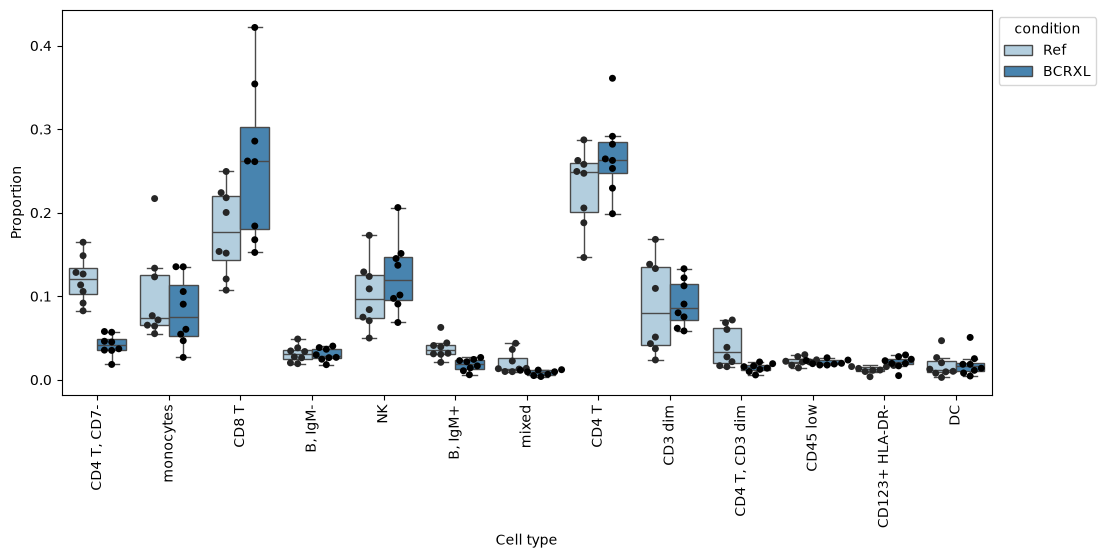

In [16]:
sccoda.plot_boxplots(sccoda_data, feature_name="condition", add_dots=True, figsize=(12, 5));

The model formula `condition + patient_id` estimates the effect of the stimulation while allowing every donor its own baseline composition. With `reference_cell_type="automatic"`, scCODA picks as reference a population that is present in all samples and varies little between them. scCODA is a Bayesian model and is fitted by sampling (a few minutes on a laptop).

In [17]:
sccoda_data = sccoda.prepare(sccoda_data, formula="condition + patient_id", reference_cell_type="automatic")
sccoda.run_nuts(sccoda_data, num_samples=5000, num_warmup=500, rng_key=1234)

• Automatic reference selection! Reference cell type set to CD45 low


scCODA calls an effect credible if it is included in the model with high probability, controlling the false discovery rate at 5% by default. The effects of the stimulation:

In [18]:
effects = sccoda.get_effect_df(sccoda_data).loc["condition[T.BCRXL]"]
effects["credible"] = sccoda.credible_effects(sccoda_data).loc["condition[T.BCRXL]"]
effects[["Inclusion probability", "log2-fold change", "credible"]].sort_values(
    "Inclusion probability", ascending=False
).round(2).head(6)

,Inclusion probability,log2-fold change,credible
Cell Type,,,
"CD4 T, CD7-",1.00,-1.48,True
"CD4 T, CD3 dim",1.00,-1.20,True
"B, IgM+",0.98,-0.99,True
CD8 T,0.97,0.54,True
mixed,0.90,-0.90,True
monocytes,0.75,0.03,False


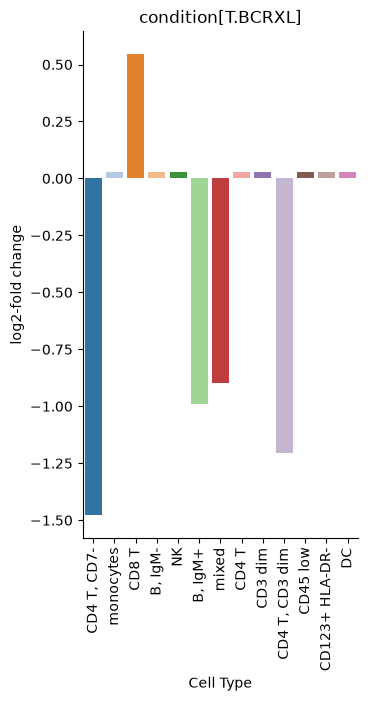

In [19]:
sccoda.plot_effects_barplot(sccoda_data, covariates=["condition"], figsize=(6, 4));

The model finds fewer IgM+ B cells, fewer CD7- and CD3-dim CD4 T cells and fewer cells of the mixed cluster in the stimulated samples, and more CD8 T cells. All changes are relative to the reference population, here the CD45 low cluster (see the output of `prepare` above). Populations without a credible effect still show a small common shift in the barplot, because the proportions have to add up to 1. After 30 minutes of stimulation, cells are unlikely to have appeared or disappeared, so such changes more likely mean that marker levels shifted (for example the cross-linker binding the B cell receptor can change the IgM signal) and moved cells between clusters. A statistically credible change in abundance is a starting point for such questions, not an answer to them.

Other scverse options for abundance are a count model per population (for example `pt.tl.PyDESeq2` on the `counts` table) and pertpy's Milo, which tests neighbourhoods of a kNN graph instead of clusters.

## Differential state

For every population and state marker we now ask whether the per-sample median changes with stimulation. We fit a linear model `~ condition + patient_id` to the 16 medians of each population with pertpy's `Statsmodels`, through `compare_groups(..., paired_by="patient_id")`. With one sample per donor and condition, this is the same as a paired t-test: it tests whether the within-donor difference is zero on average. The coefficient, which pertpy reports as `log_fc`, is here the mean difference of the arcsinh-transformed medians (stimulated minus reference). For bright signals, a difference of 1 on the arcsinh scale is about a 2.7-fold change.

In [20]:
results = []
for population in pseudobulk.obs["population"].cat.categories:
    subset = pseudobulk[pseudobulk.obs["population"] == population]
    result = pt.tl.Statsmodels.compare_groups(
        subset,
        column="condition",
        baseline="Ref",
        groups_to_compare="BCRXL",
        paired_by="patient_id",
        layer="median",
    )
    results.append(result.assign(population=population))
results = pd.concat(results, ignore_index=True).rename(columns={"variable": "marker", "log_fc": "difference"})

`compare_groups` corrects the p-values only over the markers of one population. We tested 13 populations x 14 markers = 182 hypotheses, so we redo the Benjamini-Hochberg correction over all of them:

In [21]:
results["adj_p_value"] = fdrcorrection(results["p_value"])[1]
results = results.sort_values("p_value")
results[["population", "marker", "difference", "p_value", "adj_p_value"]].head(10)

,population,marker,difference,p_value,adj_p_value
70,"B, IgM+",pS6,2.378088,1.667714e-07,0.000017
42,"B, IgM-",pS6,3.104466,1.830124e-07,0.000017
140,CD45 low,pBtk,-0.544141,4.382137e-07,0.000027
98,CD4 T,pZap70,0.026232,8.174144e-07,0.000037
56,NK,pBtk,-0.547439,3.303713e-06,0.000120
71,"B, IgM+",pPlcg2,1.771971,5.969206e-06,0.000181
99,CD4 T,pBtk,-0.471040,7.258728e-06,0.000189
14,monocytes,pBtk,-0.538002,8.312032e-06,0.000189
0,"CD4 T, CD7-",pBtk,-0.298969,9.333735e-06,0.000189
1,"CD4 T, CD7-",pZap70,0.018530,1.639280e-05,0.000262


In [22]:
significant = results["adj_p_value"] < 0.05
print(f"{significant.sum()} of {len(results)} tests with adjusted p < 0.05")

104 of 182 tests with adjusted p < 0.05


The heatmap shows the difference of every population and marker with an adjusted p-value below 0.05 (red: higher after stimulation, blue: lower; blank: not significant):

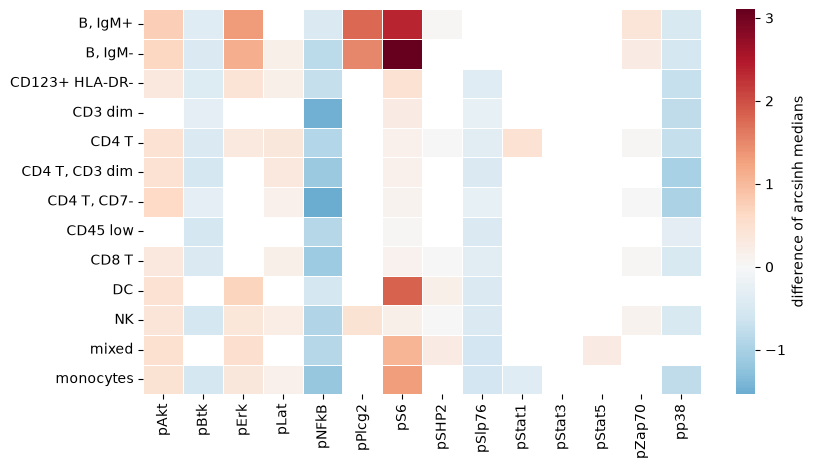

In [23]:
difference = results.pivot(index="population", columns="marker", values="difference")
adj_p = results.pivot(index="population", columns="marker", values="adj_p_value")
fig, ax = plt.subplots(figsize=(9, 5))
sns.heatmap(
    difference.where(adj_p < 0.05),
    cmap="RdBu_r",
    center=0,
    linewidths=0.5,
    cbar_kws={"label": "difference of arcsinh medians"},
    ax=ax,
)
ax.set(xlabel="", ylabel="");

The largest changes are increases of pS6 in both B cell populations, together with higher pPlcg2, pErk and pAkt in the same cells. These proteins are part of the signalling downstream of the B cell receptor, so this is the response we expect from a B cell receptor cross-linker. pS6 in B cells is also the best-known effect in this dataset (Nowicka et al., 2017; [Weber et al., 2019](https://doi.org/10.1038/s42003-019-0415-5)). pS6 also rises in monocytes and DCs, which carry Fc receptors that the cross-linker may engage as well. The paired plot shows that the increases in IgM- B cells hold in every single donor:

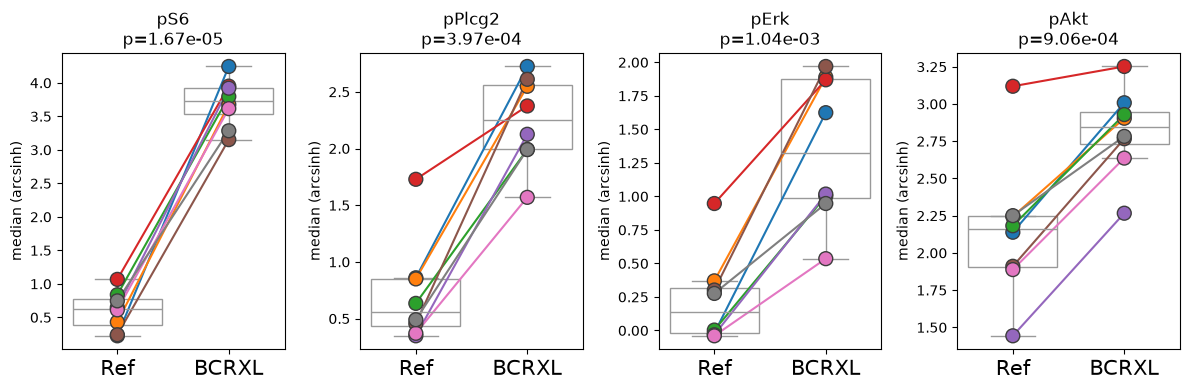

In [24]:
b_cells = pseudobulk[pseudobulk.obs["population"] == "B, IgM-"]
model = pt.tl.Statsmodels(b_cells, design="~ condition + patient_id", layer="median")
model.plot_paired(
    b_cells,
    results[results["population"] == "B, IgM-"].rename(columns={"marker": "variable"}),
    groupby="condition",
    pairedby="patient_id",
    var_names=["pS6", "pPlcg2", "pErk", "pAkt"],
    layer="median",
    y_label="median (arcsinh)",
    n_cols=4,
    panel_size=(3, 4),
    show_legend=False,
);

More than half of all tests are significant, many with small differences. Two things to keep in mind:

1. With a paired design, even small but consistent differences become significant. The adjusted p-value tells us that a change is unlikely to be zero, not that it is large or biologically relevant. Look at the size of the difference as well.
2. Some markers, such as pNFkB, pp38, pBtk and pSlp76, are lower after stimulation in almost every population, including T cells and NK cells. From this data alone we cannot tell whether this is a response to the stimulation or a difference in how the stimulated and reference samples were handled. Effects that are specific to the cells the stimulus targets, like pS6 in B cells, are easier to interpret.

## Session info

In [25]:
import session_info2

session_info2.session_info()

Package,Version
pandas,3.1.0
arviz-stats,1.3.3
mudata,0.4.1
anndata,0.13.4
matplotlib,3.11.2
pertpy,1.4.0
scanpy,1.12.4
seaborn,0.13.2
statsmodels,0.15.0
pytometry,0.2.0
